# COVID-19 Vaccine Conjoint Analysis (Wang et al., 2026 Benchmark)

In [1]:
# Step 1: Import MNL estimation utilities and load/pair the Kreps et al. (2020) COVID-19 conjoint dataset
import importlib
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wang_mnl

importlib.reload(wang_mnl)
from wang_mnl import (
    encode_design_matrix,
    evaluate_wang_metrics,
    fit_mnl_mle,
    load_covid_conjoint,
    pair_choice_sets,
)

DATA_PATH = Path("../../data/covid/dataverse_files/Kreps_etal_vax_replication_data.dta")
raw_df = load_covid_conjoint(DATA_PATH)
df_A, df_B, y_human_A, y_human_B, y_human_C = pair_choice_sets(raw_df)
X_A = encode_design_matrix(df_A)
X_B = encode_design_matrix(df_B)

print(f"Loaded {len(df_A):,} paired choice sets across {df_A['respondent'].nunique():,} respondents (d={X_A.shape[1]} features)")

Loaded 9,855 paired choice sets across 1,971 respondents (d=11 features)


In [2]:
# Step 2: Fit full-sample human ground-truth MNL regression (beta*, N = 9,855 pairs)
human_mnl_df = fit_mnl_mle(X_A, X_B, y_human_A, y_human_B, y_human_C)
beta_star = human_mnl_df["beta"].copy()
# human_mnl_df.round(4)

# Step 3: Subsample the 200 respondents (1,000 choice sets, seed=42) and fit Human Subsample Baseline MNL (beta_sub)
N_LLM_RESPONDENTS = 200
SUBSAMPLE_SEED = 42

all_respondents = np.sort(df_A["respondent"].unique())
rng = np.random.default_rng(SUBSAMPLE_SEED)
sampled_respondents = np.sort(rng.choice(all_respondents, size=N_LLM_RESPONDENTS, replace=False))

sub_mask = df_A["respondent"].isin(sampled_respondents).to_numpy()
sub_df_A = df_A.loc[sub_mask].reset_index(drop=True)
sub_df_B = df_B.loc[sub_mask].reset_index(drop=True)
X_A_sub = X_A[sub_mask]
X_B_sub = X_B[sub_mask]
y_human_A_sub = y_human_A[sub_mask]
y_human_B_sub = y_human_B[sub_mask]
y_human_C_sub = y_human_C[sub_mask]

# Ordered list of (respondent, pair_id) keys for aligning model prediction JSONL files
subsample_keys = [(int(r["respondent"]), int(r["pair_id"])) for r in sub_df_A[["respondent", "pair_id"]].to_dict("records")]

human_sub_mnl_df = fit_mnl_mle(X_A_sub, X_B_sub, y_human_A_sub, y_human_B_sub, y_human_C_sub)
beta_human_sub = human_sub_mnl_df["beta"].copy()
human_sub_metrics = evaluate_wang_metrics(beta_human_sub, beta_star)

print(
    f"Human Subsample Baseline (n={len(sub_df_A):,} pairs) vs. Full Human (beta*): "
    f"MAPE = {human_sub_metrics['MAPE (%)']:.2f}%, MSE = {human_sub_metrics['MSE']:.4f}"
)
human_sub_mnl_df.assign(full_human_beta=beta_star, diff=beta_human_sub - beta_star).round(4)

Human Subsample Baseline (n=1,000 pairs) vs. Full Human (beta*): MAPE = 22.08%, MSE = 0.0065


,feature,beta,se,z,p_value,full_human_beta,diff
label,,,,,,,
Efficacy: 70% (vs. 50%),efficacy_70,0.2802,0.1118,2.5064,0.0122,0.3607,-0.0806
Efficacy: 90% (vs. 50%),efficacy_90,0.6791,0.1104,6.1524,0.0000,0.7456,-0.0665
Duration: 5 years (vs. 1 year),duration_5yr,0.2770,0.0920,3.0091,0.0026,0.2608,0.0161
"Major side effects: 1 in 1,000,000 (vs. 1 in 10,000)",majorside_1m,0.3890,0.0907,4.2903,0.0000,0.3042,0.0848
Minor side effects: 1 in 30 (vs. 1 in 10),minorside_30,0.0852,0.0905,0.9419,0.3462,0.0755,0.0097
FDA: Emergency Use Authorization (vs. Full approval),fda_eua,-0.1126,0.0920,-1.2233,0.2212,-0.1155,0.0029
Origin: United Kingdom (vs. United States),origin_uk,-0.0256,0.1090,-0.2350,0.8142,-0.1402,0.1146
Origin: China (vs. United States),origin_china,-0.4255,0.1130,-3.7640,0.0002,-0.5695,0.1441
Endorsed: Joe Biden (vs. Donald Trump),endorsed_biden,0.0996,0.1233,0.8082,0.4190,0.0952,0.0044


# Model Predictions & MNL Regressions

In [14]:
# Step 4: Dynamically discover all collected Gemini & Kev JSONL datasets and fit MNL MLE regressions
importlib.reload(wang_mnl)
from wang_mnl import load_all_model_regressions, plot_wang_error_comparison

model_mnl_dfs = load_all_model_regressions(
    X_A_sub,
    X_B_sub,
    subsample_keys,
    gemini_data_dir="../../proprietary-llms/gemini/data",
    kev_data_dir="data",
)
print(f"Dynamically loaded and fitted {len(model_mnl_dfs)} model datasets:")
for name in model_mnl_dfs:
    print(" -", name)

[WARNING] gemini-4-argon_HIGH_random.jsonl: dropped 16/1000 non-A/B/C refusal responses (fitting on valid n=984; first 3 refusal keys: [(112, 5), (530, 2), (581, 5)])
Dynamically loaded and fitted 12 model datasets:
 - gemini-3.5-flash-lite (HIGH, Respondent Persona, n=1000)
 - gemini-3.5-flash-lite (HIGH, Random Persona, n=1000)
 - gemini-3.5-flash-lite (MINIMAL, Respondent Persona, n=1000)
 - gemini-3.5-flash-lite (MINIMAL, Random Persona, n=1000)
 - gemini-4-argon (HIGH, Respondent Persona, n=1000)
 - gemini-4-argon (HIGH, Random Persona, n=984)
 - gemini-4-argon (LOW, Respondent Persona, n=1000)
 - gemini-4-argon (LOW, Random Persona, n=1000)
 - jaredpalmer/kev-9b (Respondent Persona, n=1000)
 - jaredpalmer/kev-9b (Random Persona, n=1000)
 - kev-9b-resp-issp+twin2k-grouped-newvalid/best (Respondent Persona, n=1000)
 - kev-9b-resp-issp+twin2k-grouped-newvalid/best (Random Persona, n=1000)


In [15]:
# Step 5: Compare all estimators against Full Human (beta*) and Same Human Subsample (beta_sub) using Wang (2026) MAPE & MSE
estimators_beta = {
    f"Human Subsample Baseline (n={len(sub_df_A)})": beta_human_sub,
    **{name: df_m["beta"] for name, df_m in model_mnl_dfs.items()},
}

comparison_rows = {}
for name, b_hat in estimators_beta.items():
    vs_full = evaluate_wang_metrics(b_hat, beta_star)
    vs_sub = evaluate_wang_metrics(b_hat, beta_human_sub)
    comparison_rows[name] = {
        "MAPE vs. Full Human (%)": vs_full["MAPE (%)"],
        "MSE vs. Full Human": vs_full["MSE"],
        "MAPE vs. Human Subsample (%)": vs_sub["MAPE (%)"],
        "MSE vs. Human Subsample": vs_sub["MSE"],
    }

comparison_metrics_df = pd.DataFrame(comparison_rows).T.sort_values("MSE vs. Full Human", ascending=True)
print("=== Wang (2026) Error Metrics (MAPE & MSE) vs. Full Human (beta*) and Same Human Subsample (sorted best to worst on MSE) ===")
display(comparison_metrics_df.round(4))

coef_comparison_df = pd.DataFrame({
    "Full Human (beta*, N=9855)": beta_star,
    **estimators_beta,
})
# coef_comparison_df.round(4)

=== Wang (2026) Error Metrics (MAPE & MSE) vs. Full Human (beta*) and Same Human Subsample (sorted best to worst on MSE) ===


,MAPE vs. Full Human (%),MSE vs. Full Human,MAPE vs. Human Subsample (%),MSE vs. Human Subsample
Human Subsample Baseline (n=1000),22.0777,0.0065,0.0000,0.0000
"kev-9b-resp-issp+twin2k-grouped-newvalid/best (Random Persona, n=1000)",51.7606,0.0205,105.6160,0.0354
"kev-9b-resp-issp+twin2k-grouped-newvalid/best (Respondent Persona, n=1000)",56.5673,0.0239,110.0056,0.0320
"jaredpalmer/kev-9b (Random Persona, n=1000)",110.7824,0.0932,245.4392,0.1350
"jaredpalmer/kev-9b (Respondent Persona, n=1000)",87.4472,0.0982,194.1886,0.1394
"gemini-3.5-flash-lite (MINIMAL, Respondent Persona, n=1000)",203.6390,0.5925,337.9706,0.6634
"gemini-3.5-flash-lite (HIGH, Respondent Persona, n=1000)",335.8449,1.1984,415.9056,1.2626
"gemini-4-argon (LOW, Respondent Persona, n=1000)",376.7427,1.7637,605.5651,1.8879
"gemini-4-argon (HIGH, Respondent Persona, n=1000)",395.1132,2.1687,576.9981,2.3092
"gemini-3.5-flash-lite (MINIMAL, Random Persona, n=1000)",531.6817,3.2073,750.2698,3.3150


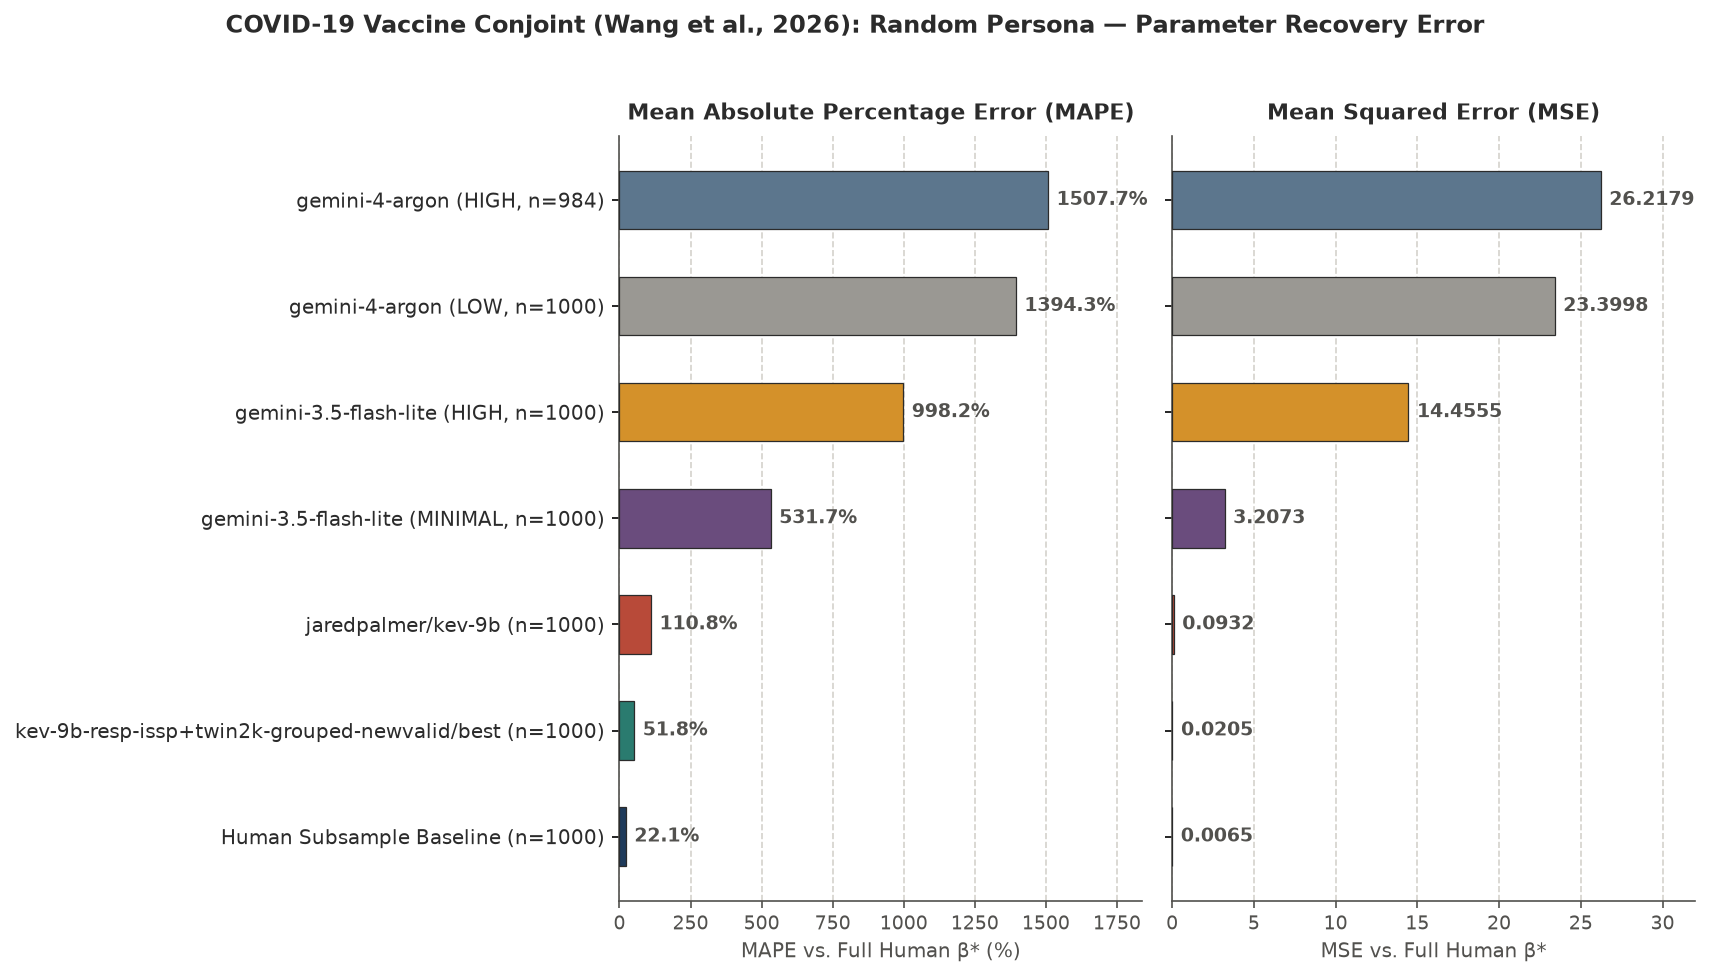

In [16]:
# Step 6a: Plot Random Persona models (plus Human Subsample Baseline) sorted best-to-worst on MSE vs. Full Human (beta*)
fig_random = plot_wang_error_comparison(
    comparison_metrics_df,
    palette="nature",
    persona_filter="Random Persona",
    sort_by="MSE vs. Full Human",
)
plt.show()

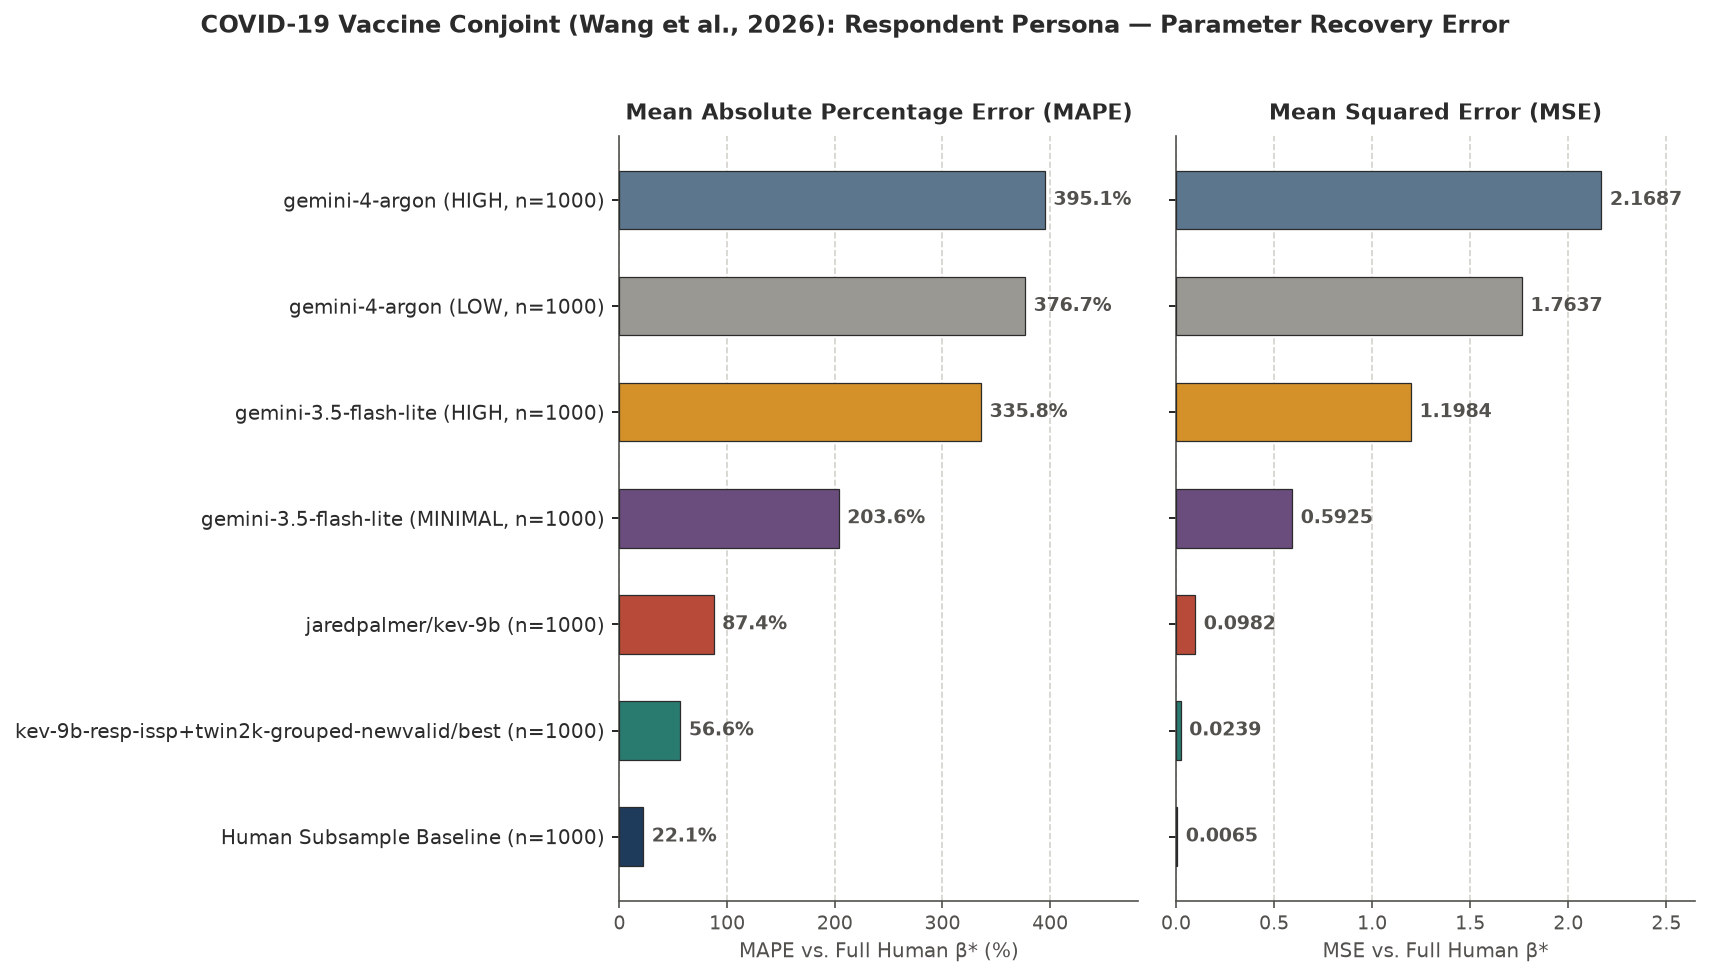

In [17]:
# Step 6b: Plot Respondent Persona models (plus Human Subsample Baseline) sorted best-to-worst on MSE vs. Full Human (beta*)
fig_persona = plot_wang_error_comparison(
    comparison_metrics_df,
    palette="nature",
    persona_filter="Respondent Persona",
    sort_by="MSE vs. Full Human",
)
plt.show()